# IBM AML HI-Small — Full transaction-graph system

**Một dataset, một full input, một transaction index, một benchmark.** Notebook này chạy riêng IBM AML HI-Small: Task 1 integrity → Task 2 Degree/PageRank → Task 4 LPA → Task 3 baseline/motif → common point-in-time feature table → 8 factorial ablations + novelty control → validation-frozen test → predictions/model/evidence verification.

Code thuật toán nằm trong `.py`; mỗi cell import đúng hàm của bước đó để Ctrl+click đến source. Không dùng sample làm kết quả full. Các bảng nhỏ là view/aggregate từ full graph, còn mọi account/transaction được lưu trong Parquet ở thư mục run mới.

**Chỉ chạy một workload nặng.** Chọn kernel Windows `.venv` Python 3.12, JDK17; heap 5 GiB/job cap 8 GiB, CPU10%, tối đa 2 logical CPUs và reserve giữ nguyên. Một số bước full có thể lâu; không mở notebook/Spark thứ hai để chạy cùng.


## 1. Môi trường và bảo vệ tài nguyên

Cell khởi tạo kiểm tra native Windows, dependency pins và guard trước Java. Guard từ chối admission thì dừng, không hạ reserve hoặc tự retry.


In [1]:
from pathlib import Path
import sys
from IPython.display import display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'requirements.txt').exists() and (p / 'src').is_dir())
sys.path.insert(0, str(repo))
from src.motif.presentation import start_system_session
session = start_system_session('ibm_aml')
display(session.runtime)


[RESOURCE] One workload; CPU hard cap 10%; <=2 logical CPUs; job commit cap 8.0 GiB; RAM reserve 7.9 GiB


[RESOURCE] Effective Spark local[2], heap 5120m; spill before increasing RAM


,setting,value
0,dataset,ibm_aml
1,system,Windows
2,python,3.12.10
3,spark,3.5.1
4,graphframes,0.12.2
5,java,17.0.20.1
6,master,local[2]
7,driver_memory,5120m
8,pip_check,PASS
9,cpu_hard_cap_percent,10


## 2. Protocol khai báo trước khi chạy

3 validation folds: train ≤40% / validation (40,50], train ≤50% / validation (50,65], train ≤65% / validation (65,80]. Refit đến 80%, test sau đó; giữ timestamp ties. Snapshot boundaries 20/40/50/65/80%; training rows cũng chỉ dùng snapshot quá khứ. Block đầu chưa có snapshot centrality/community: các feature của hai nhóm này bằng 0 và có unseen flags. Motif vẫn dùng strict-past transactions của từng dòng; các giá trị 0 không phải dự đoán fraud.

8 family factorial là mọi tổ hợp của 3 nhóm graph, luôn có transaction features. Thêm matched-tree transaction+novelty control để tách hiệu ứng cold-start; tổng 9 families. Cùng cây depth=5/min-leaf=50/seed=2026 và class-weight rule. Ngưỡng chọn F1 validation; AP và review budgets 0,1/0,5/1% được báo riêng. Weighted score không phải calibrated probability.


In [2]:
from src.motif.config import FullSystemConfig, SYSTEM_FAMILY_GROUPS

config = FullSystemConfig()
display(config.as_dict())
display(SYSTEM_FAMILY_GROUPS)


{'analysis': {'windows_hours': (24, 168),
  'fold_fractions': (0.4, 0.5, 0.65, 0.8),
  'score_thresholds': (0.001,
   0.005,
   0.01,
   0.02,
   0.05,
   0.1,
   0.2,
   0.3,
   0.5,
   0.7,
   0.9,
   0.99),
  'tree_depth': 5,
  'minimum_leaf_rows': 50,
  'seed': 2026,
  'example_limit': 5,
  'driver_memory': '5g',
  'parallelism': 2},
 'snapshot_fractions': (0.2, 0.4, 0.5, 0.65, 0.8),
 'review_fractions': (0.001, 0.005, 0.01),
 'pagerank_iterations': 10,
 'lpa_iterations': 5,
 'partitions': 64}

{'transaction_only': (),
 'transaction_novelty': ('novelty',),
 'transaction_centrality': ('centrality',),
 'motif_assisted': ('motif',),
 'transaction_community': ('community',),
 'full_fusion': ('centrality', 'motif', 'community'),
 'without_centrality': ('motif', 'community'),
 'without_motifs': ('centrality', 'community'),
 'without_community': ('centrality', 'motif')}

## 3. Full input, integrity và chỉ mục giao dịch chung

Không downsample. `event_id` được tạo một lần cho mỗi physical row rồi persist; duplicate records vẫn là các giao dịch riêng. Các nhánh dùng cùng table này. Output directory được tạo mới, không ghi đè evidence trước. Full vertex metadata/balance chỉ dùng mô tả, không đưa balance cuối kỳ vào detector.


In [3]:
from src.motif.pipeline import start_full_system
from src.motif.presentation import system_protocol_table

run = start_full_system(session.spark, 'ibm_aml', config=config)
display(run.record['integrity'])
display(run.record['support'])
display(system_protocol_table(run))
print('Full run directory:', run.output_dir)


[SYSTEM] Indexed 5,078,345 full transactions once; cutoffs=(1662040800, 1662203520, 1662354840, 1662489900, 1662628020)


{'num_vertices': 518581,
 'num_edges': 5078345,
 'null_vertices': 0,
 'null_edges': 0,
 'dangling_src': 0,
 'dangling_dst': 0,
 'dangling_edges': 0,
 'self_loops': 591212}

{'n': 5078345,
 'unique_ids': 5078345,
 'positives': 5177.0,
 'first_step': 1661965200,
 'last_step': 1663492680}

,time_block,transactions,positives,first_step,last_step,positive_rate,first_time_UTC,last_time_UTC
0,0,1014492,286.0,1661965200,1662040800,0.000282,2022-08-31 17:00:00+00:00,2022-09-01 14:00:00+00:00
1,1,1015192,761.0,1662040860,1662203520,0.000750,2022-09-01 14:01:00+00:00,2022-09-03 11:12:00+00:00
2,2,508995,699.0,1662203580,1662354840,0.001373,2022-09-03 11:13:00+00:00,2022-09-05 05:14:00+00:00
3,3,759554,808.0,1662354900,1662489900,0.001064,2022-09-05 05:15:00+00:00,2022-09-06 18:45:00+00:00
4,4,762916,824.0,1662489960,1662628020,0.001080,2022-09-06 18:46:00+00:00,2022-09-08 09:07:00+00:00
5,5,1017196,1799.0,1662628080,1663492680,0.001769,2022-09-08 09:08:00+00:00,2022-09-18 09:18:00+00:00


Full run directory: D:\Desktop_informations\SGK năm 4\SGK kì 1 năm 4\BigData - Phong\Project_graphX\graphguard-amls-detection\results\full_system\ibm_aml\run_20261023T165404547138Z


### Full raw–Parquet reconciliation
Đối chiếu hai chiều vertices và edges trên toàn bộ IBM HI-Small, giữ duplicate transactions. Tái lập mapping timestamp của ETL bằng Asia/Saigon rồi khôi phục UTC. Balance cuối kỳ không làm feature.


In [4]:
from src.motif.pipeline import full_system_raw_reconciliation

display(full_system_raw_reconciliation(run))


[SYSTEM] raw_reconciliation: PASS


{'status': 'PASS',
 'elapsed_seconds': 159.04,
 'tables': [{'table': 'vertices',
   'raw_minus_parquet': 0,
   'parquet_minus_raw': 0,
   'status': 'PASS'},
  {'table': 'edges',
   'raw_minus_parquet': 0,
   'parquet_minus_raw': 0,
   'status': 'PASS'}],
 'timezone': 'Asia/Saigon for raw timestamp mapping',
 'vertex_balance': 'full raw contract',
 'raw_files': [{'path': 'D:\\Desktop_informations\\SGK năm 4\\SGK kì 1 năm 4\\BigData - Phong\\Project_graphX\\graphguard-amls-detection\\data\\raw\\ibm_aml\\HI-Small_Trans.csv',
   'bytes': 475664283,
   'sha256': 'b19d39f515523373f991b689c07e11e7b0b95c17a2c27a87d91584ae16c5b040'},
  {'path': 'D:\\Desktop_informations\\SGK năm 4\\SGK kì 1 năm 4\\BigData - Phong\\Project_graphX\\graphguard-amls-detection\\data\\raw\\ibm_aml\\HI-Small_accounts.csv',
   'bytes': 34053187,
   'sha256': '786808526e33cfc441212dd6fccda7edfc24172149bed59c6ef59b186836b014'}],
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.

## 4. Degree và PageRank trên toàn graph

PageRank10/reset=0,15; backend SQL disk-checkpoint đối chiếu independent reference/GraphX trên fixture. Giữ đa cạnh/self-loop, chuẩn hóa cuối để tổng PageRank=N; không gọi score này là xác suất fraud. `account_metrics.parquet` chứa mọi account; top10 và degree plot chỉ là view trình bày.

Đọc scatter: mỗi chấm là số accounts có một mức degree; hai trục log giúp thấy phần đuôi. Degree 0 vẫn nằm trong CSV/Parquet, không vẽ trên log axes. Backend dùng chung nằm trong `src/paysim/metrics.py`; dataset được chọn bằng IBM input của `run`, không đọc dữ liệu PaySim.


[SYSTEM] PageRank iteration 1/10 persisted


[SYSTEM] PageRank iteration 2/10 persisted


[SYSTEM] PageRank iteration 3/10 persisted


[SYSTEM] PageRank iteration 4/10 persisted


[SYSTEM] PageRank iteration 5/10 persisted


...

[SYSTEM] PageRank iteration 8/10 persisted


[SYSTEM] PageRank iteration 9/10 persisted


[SYSTEM] PageRank iteration 10/10 persisted


[SYSTEM] centrality_full: PASS


{'status': 'PASS',
 'elapsed_seconds': 45.859,
 'accounts': 518581,
 'degree_sum': 10156690,
 'rank_sum': 518581.00000070164,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 4.11,
  'minimum_available_ram_gib': 15.5,
  'maximum_host_cpu_percent': 29.3,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

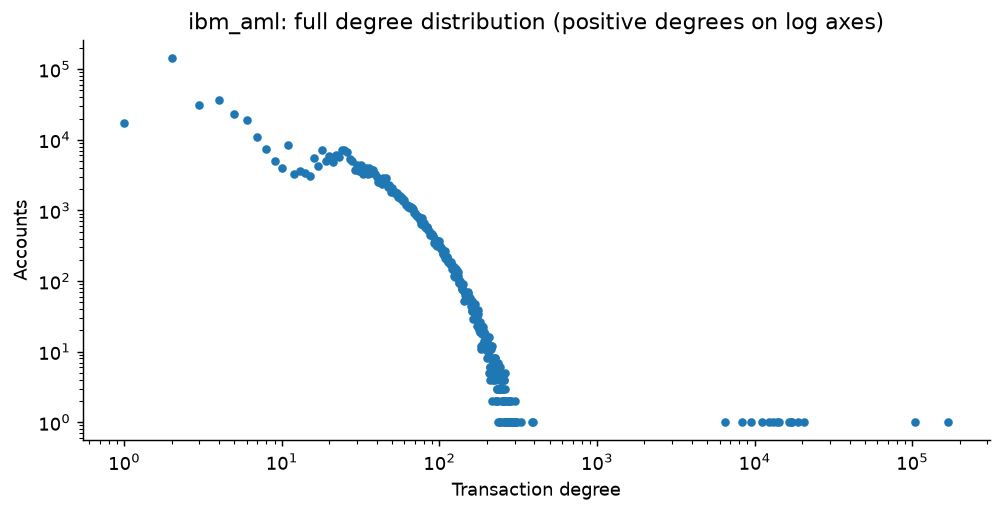

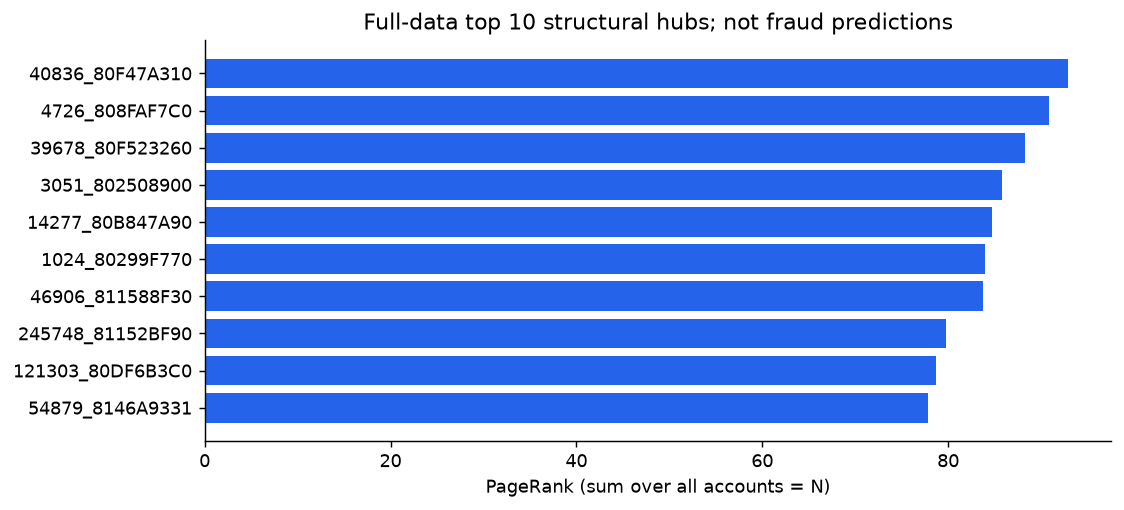

,id,pagerank,inDegree,outDegree,degree
0,40836_80F47A310,92.916825,159,2,161
1,4726_808FAF7C0,90.901724,90,1,91
2,39678_80F523260,88.309695,84,2,86
3,3051_802508900,85.792714,78,2,80
4,14277_80B847A90,84.680007,85,1,86
5,1024_80299F770,83.987381,80,2,82
6,46906_811588F30,83.774530,76,1,77
7,245748_81152BF90,79.785057,69,1,70
8,121303_80DF6B3C0,78.692572,71,2,73
9,54879_8146A9331,77.805299,83,1,84


In [5]:
from src.motif.pipeline import full_system_centrality
from src.motif.presentation import plot_system_centrality

display(full_system_centrality(run))
display(plot_system_centrality(run))


## 5. LPA và all-community profiles trên full data

5 vòng modal-neighbor updates, message hai chiều theo mỗi transaction, giữ đa cạnh/self-loop và isolate. Backend SQL dùng seed xxhash64 ổn định, kiểm tra collision và tie chọn nhãn nhỏ nhất; không yêu cầu cùng partition với GraphX khi hòa phiếu. Numeric label không phải fraud class hoặc feature. Assignments/all-summary/amounts theo currency được lưu đầy đủ và đối chiếu SQL độc lập. Fraud statistics ở đây là **posthoc audit**.

Mỗi chấm biểu diễn số communities có cùng số thành viên; hai trục log. Nhiều cụm nhỏ hay một cụm lớn đều chưa chứng minh fraud. Backend SQL dùng chung nhận graph IBM từ pipeline.


[SYSTEM] LPA iteration 1/5 persisted


[SYSTEM] LPA iteration 2/5 persisted


[SYSTEM] LPA iteration 3/5 persisted


[SYSTEM] LPA iteration 4/5 persisted


[SYSTEM] LPA iteration 5/5 persisted


[SYSTEM] communities_full: PASS


{'status': 'PASS',
 'elapsed_seconds': 93.356,
 'communities': 314722,
 'accounts': 518581,
 'transactions': 5078345,
 'positives': 5177,
 'internal_edges': 852930,
 'cross_edges': 4225415,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 4.17,
  'minimum_available_ram_gib': 15.5,
  'maximum_host_cpu_percent': 29.3,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

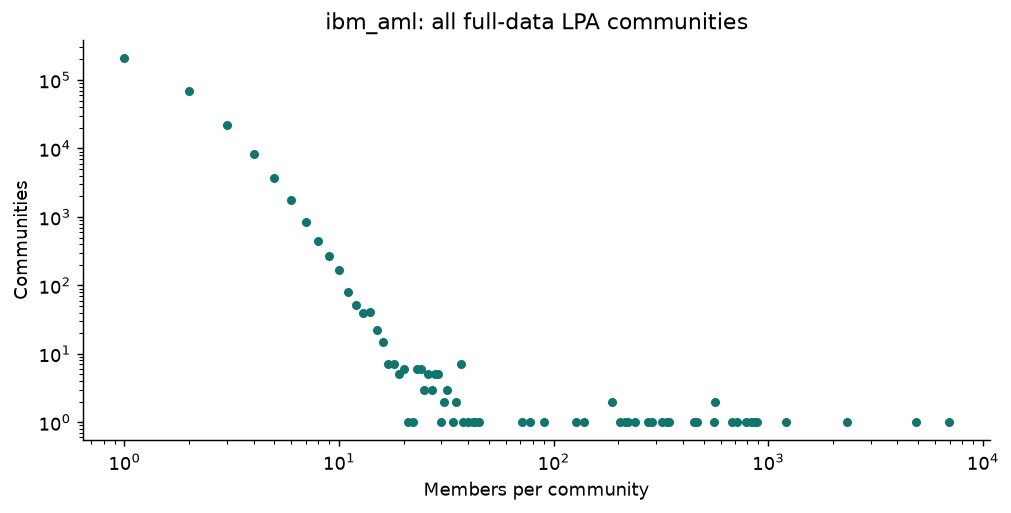

,label,member_count,unique_banks_count,total_tx_count,positive_tx_count,internal_tx_count,cross_tx_count
0,2841208552804025435,6935,1274,42119,69,8289,33830
1,-6017008472124481862,4870,831,32202,45,6293,25909
2,-1845136380396678331,2327,1259,179865,248,2278,177587
3,1645034660210658271,1212,720,109143,166,902,108241
4,-403586342733232231,883,178,5586,2,1050,4536
5,-8152616635486292743,854,137,6204,7,1170,5034
6,-7416694367604068795,828,133,6278,4,1012,5266
7,-735310874234786089,788,154,4757,14,1142,3615
8,-6006891417238418498,716,122,5108,6,917,4191
9,5480051028422924661,676,139,4193,4,767,3426


In [6]:
from src.motif.pipeline import full_system_communities
from src.motif.presentation import plot_system_communities

display(full_system_communities(run))
display(plot_system_communities(run))


## 6. Baseline motif theo đề và interpretation boundary

Các query IBM gốc được chạy trên full graph. Cycles lọc nhãn là label audit, không phải detector phát hiện mù; query USD >10.000 được báo riêng dù có thể bằng 0. Bước này không cấp nhãn/feature cho classifier.


In [7]:
from src.motif.pipeline import full_system_baseline

baseline = full_system_baseline(run)
display(baseline.summary)
display(baseline.examples.head(5))


[SYSTEM] motif_baseline: PASS


,dataset,fraud_edges,label_audit_raw_cycles,directed_account_cycles,transaction_combinations,USD_above_10000_cycles
0,ibm_aml,5177,7473,54,2491,0


,a,b,c,transaction_combinations
0,119_811C597B0,222_811B83280,48309_811C599A0,490
1,148350_811FFF630,148350_812D0C3C0,50528_812D0C600,360
2,119_811C597B0,150240_812D22980,48309_811C599A0,300
3,119_811C597B0,48309_811C599A0,150240_812D22980,280
4,119_811C597B0,222_811B83280,150240_812D22980,245


## 7. Causal motif features cho mọi transaction

Fan-in/out, relay, reciprocal, 3-cycle và role-history trong cửa sổ 24/168 giờ. Witness phải trước transaction quyết định; cùng timestamp không giả định thứ tự. Currency/FX được giữ đúng đơn vị. Giao dịch không có motif, self-loop hoặc FX vẫn nằm trong population đánh giá.


In [8]:
from src.motif.pipeline import full_system_motif_features

display(full_system_motif_features(run))


Features: star histories via expiry-prefix sums


Features: reciprocal and same-partner histories


Features: directed topology and chronological cycle evidence


[SYSTEM] motif_features: PASS


{'status': 'PASS',
 'elapsed_seconds': 373.247,
 'rows': 5078345,
 'unique_ids': 5078345,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 6.0,
  'minimum_available_ram_gib': 14.37,
  'maximum_host_cpu_percent': 70.8,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

## 8. Feature table chung và snapshots quá khứ

Bước này chạy PageRank/LPA trên 5 prefix, không dùng account metrics/community của cuối toàn dataset cho các dòng trước đó. Motif dùng strict-past history; centrality/community có lag snapshot được ghi bằng `snapshot_as_of`. Train/validation/test đều tuân thủ điều kiện as-of < decision. Unknown account được đánh dấu, không tự gọi là fraud.

Đây có thể là bước dài nhất. Mọi row được join đúng một lần, `rows = unique_ids = full transactions`; predicate future snapshot phải bằng 0.

Seen/unseen là so với cutoff snapshot. Account xuất hiện lần đầu trong block vẫn unseen ở snapshot, dù motif có thể dùng giao dịch trước đó trong block. Đây là lag đã khai báo, không phải mất dữ liệu.


In [9]:
from src.motif.pipeline import full_system_feature_table

display(full_system_feature_table(run))


[SYSTEM] Historical snapshot 1/5, cutoff=1662040800


[SYSTEM] PageRank iteration 1/10 persisted


[SYSTEM] PageRank iteration 2/10 persisted


[SYSTEM] PageRank iteration 3/10 persisted


[SYSTEM] PageRank iteration 4/10 persisted


...

[SYSTEM] LPA iteration 3/5 persisted


[SYSTEM] LPA iteration 4/5 persisted


[SYSTEM] LPA iteration 5/5 persisted


[SYSTEM] common_features: PASS


{'status': 'PASS',
 'elapsed_seconds': 949.266,
 'rows': 5078345,
 'unique_ids': 5078345,
 'future_snapshot_rows': 0,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 6.0,
  'minimum_available_ram_gib': 14.37,
  'maximum_host_cpu_percent': 70.8,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

## 9. Walk-forward và lựa chọn ngưỡng trước test

27 fits = 9 family × 3 folds; preprocessing/class weights chỉ fit từ prefix. Chọn family/threshold bằng mean F1 validation, tie-break worst fold, ít FP và model đơn giản. Không chọn lại sau khi xem test. Nếu không có validation TP thì ABSTAIN.


[SYSTEM] Validation 1/3: transaction_only, train<=1662203520, validation<=1662354840


[SYSTEM] Validation 1/3: transaction_novelty, train<=1662203520, validation<=1662354840


[SYSTEM] Validation 1/3: transaction_centrality, train<=1662203520, validation<=1662354840


[SYSTEM] Validation 1/3: motif_assisted, train<=1662203520, validation<=1662354840


[SYSTEM] Validation 1/3: transaction_community, train<=1662203520, validation<=1662354840


...

[SYSTEM] Validation 3/3: without_centrality, train<=1662489900, validation<=1662628020


[SYSTEM] Validation 3/3: without_motifs, train<=1662489900, validation<=1662628020


[SYSTEM] Validation 3/3: without_community, train<=1662489900, validation<=1662628020


[SYSTEM] validation: PASS


,family,threshold,mean_F1,worst_F1,std_F1,mean_precision,TP,FP,FN,transactions,folds
0,full_fusion,0.5,0.100478,0.074930,0.033145,0.062892,656,10944,1675,2031465,3
1,without_community,0.5,0.100383,0.074930,0.033197,0.062810,657,10982,1674,2031465,3
2,without_centrality,0.5,0.098106,0.074930,0.029137,0.060198,670,11316,1661,2031465,3
3,motif_assisted,0.5,0.098011,0.074930,0.029184,0.060116,671,11354,1660,2031465,3
4,motif_assisted,0.7,0.092715,0.014581,0.068247,0.075160,427,4464,1904,2031465,3
5,without_centrality,0.7,0.092602,0.014581,0.068172,0.075061,427,4473,1904,2031465,3
6,without_community,0.7,0.091803,0.014581,0.067298,0.074426,425,4499,1906,2031465,3
7,full_fusion,0.7,0.091691,0.014581,0.067220,0.074327,425,4508,1906,2031465,3
8,full_fusion,0.3,0.074422,0.064837,0.009341,0.041337,911,21502,1420,2031465,3
9,without_community,0.3,0.074405,0.064787,0.009367,0.041324,912,21540,1419,2031465,3


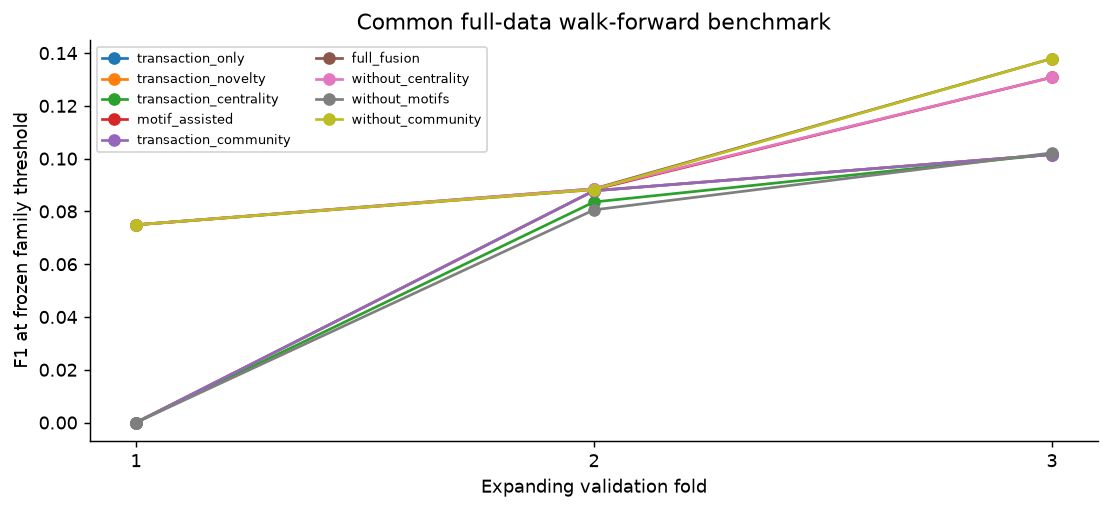

,threshold,mean_F1,worst_F1,FP
transaction_only,0.5,0.063136,0.0,11733
transaction_novelty,0.5,0.063136,0.0,11733
transaction_centrality,0.5,0.061759,0.0,10717
motif_assisted,0.5,0.098011,0.07493,11354
transaction_community,0.5,0.063136,0.0,11733
full_fusion,0.5,0.100478,0.07493,10944
without_centrality,0.5,0.098106,0.07493,11316
without_motifs,0.5,0.060922,0.0,11167
without_community,0.5,0.100383,0.07493,10982


In [10]:
from src.motif.pipeline import full_system_validation
from src.motif.presentation import plot_system_validation

leaderboard = full_system_validation(run)
display(leaderboard.head(12))
display(plot_system_validation(run))


## 10. Frozen refit, full test, model export và replay

Mọi family refit đúng cùng prefix đến 80%; mỗi giao dịch test có một score/alert. Truth chỉ join khi fit training hoặc đánh giá. Export predictions cho cả 8 factorial ablations + novelty control, model/scales và TP/FP/FN examples. Reload model được chọn và replay toàn test để kiểm tra score khớp. Test này đã từng được nghiên cứu trong project: **reused internal temporal holdout**, không phải untouched benchmark.


In [11]:
from src.motif.pipeline import full_system_test

metrics = full_system_test(run)
display(metrics[['model', 'threshold', 'TP', 'FP', 'FN', 'TN',
                 'precision', 'recall', 'F1', 'average_precision',
                 'alert_rate', 'selected_on_validation']])
display(metrics[['model','precision_low95','precision_high95','recall_low95','recall_high95']])


[SYSTEM] Frozen refit/test: transaction_only


[SYSTEM] Frozen refit/test: transaction_novelty


[SYSTEM] Frozen refit/test: transaction_centrality


[SYSTEM] Frozen refit/test: motif_assisted


[SYSTEM] Frozen refit/test: transaction_community


...

[SYSTEM] Frozen refit/test: without_motifs


[SYSTEM] Frozen refit/test: without_community


[SYSTEM] frozen_test: PASS


,model,threshold,TP,FP,FN,TN,precision,recall,F1,average_precision,alert_rate,selected_on_validation
0,transaction_only,0.5,914,10075,885,1005322,0.083174,0.508060,0.142947,0.053897,0.010803,False
1,transaction_novelty,0.5,914,10075,885,1005322,0.083174,0.508060,0.142947,0.053897,0.010803,False
2,transaction_centrality,0.5,934,10309,865,1005088,0.083074,0.519177,0.143230,0.054386,0.011053,False
3,motif_assisted,0.5,489,4519,1310,1010878,0.097644,0.271818,0.143676,0.054463,0.004923,False
4,transaction_community,0.5,914,10075,885,1005322,0.083174,0.508060,0.142947,0.053897,0.010803,False
5,full_fusion,0.5,532,5190,1267,1010207,0.092974,0.295720,0.141471,0.056662,0.005625,True
6,without_centrality,0.5,489,4519,1310,1010878,0.097644,0.271818,0.143676,0.054463,0.004923,False
7,without_motifs,0.5,959,10916,840,1004481,0.080758,0.533074,0.140266,0.055714,0.011674,False
8,without_community,0.5,507,4583,1292,1010814,0.099607,0.281823,0.147191,0.056127,0.005004,False


,model,precision_low95,precision_high95,recall_low95,recall_high95
0,transaction_only,0.078156,0.088484,0.484966,0.531120
1,transaction_novelty,0.078156,0.088484,0.484966,0.531120
2,transaction_centrality,0.078114,0.088319,0.496073,0.542200
3,motif_assisted,0.089728,0.106176,0.251762,0.292846
4,transaction_community,0.078156,0.088484,0.484966,0.531120
5,full_fusion,0.085721,0.100774,0.275085,0.317226
6,without_centrality,0.089728,0.106176,0.251762,0.292846
7,without_motifs,0.075992,0.085795,0.509974,0.556033
8,without_community,0.091679,0.108139,0.261516,0.303060


## 11. Đọc kết quả: cùng mẫu số và ngân sách review

Không kết luận fusion tốt hơn chỉ vì đã code/chạy PASS. Đọc baseline và full/drop-group ablations cùng nhau. PR/AP xử lý score ties theo nhóm; review budget chọn đúng K, tie-break content key rồi common event ID, không dùng nhãn. F1-threshold alerts và Top-K review là hai operating policies khác nhau. CI Wilson trong CSV chưa điều chỉnh tương quan account/time.

Bắt đầu từ dòng `selected_on_validation=True`, rồi đối chiếu transaction-only và full/drop-group ablations. `isFraud` giữ nhãn gốc; `alert` là dự đoán. Các score trong bảng nằm ở thang 0–1; nhân 100 để đọc phần trăm. CSV `review_budgets.csv` lưu đúng K và TP@K cho các điểm trên đồ thị.


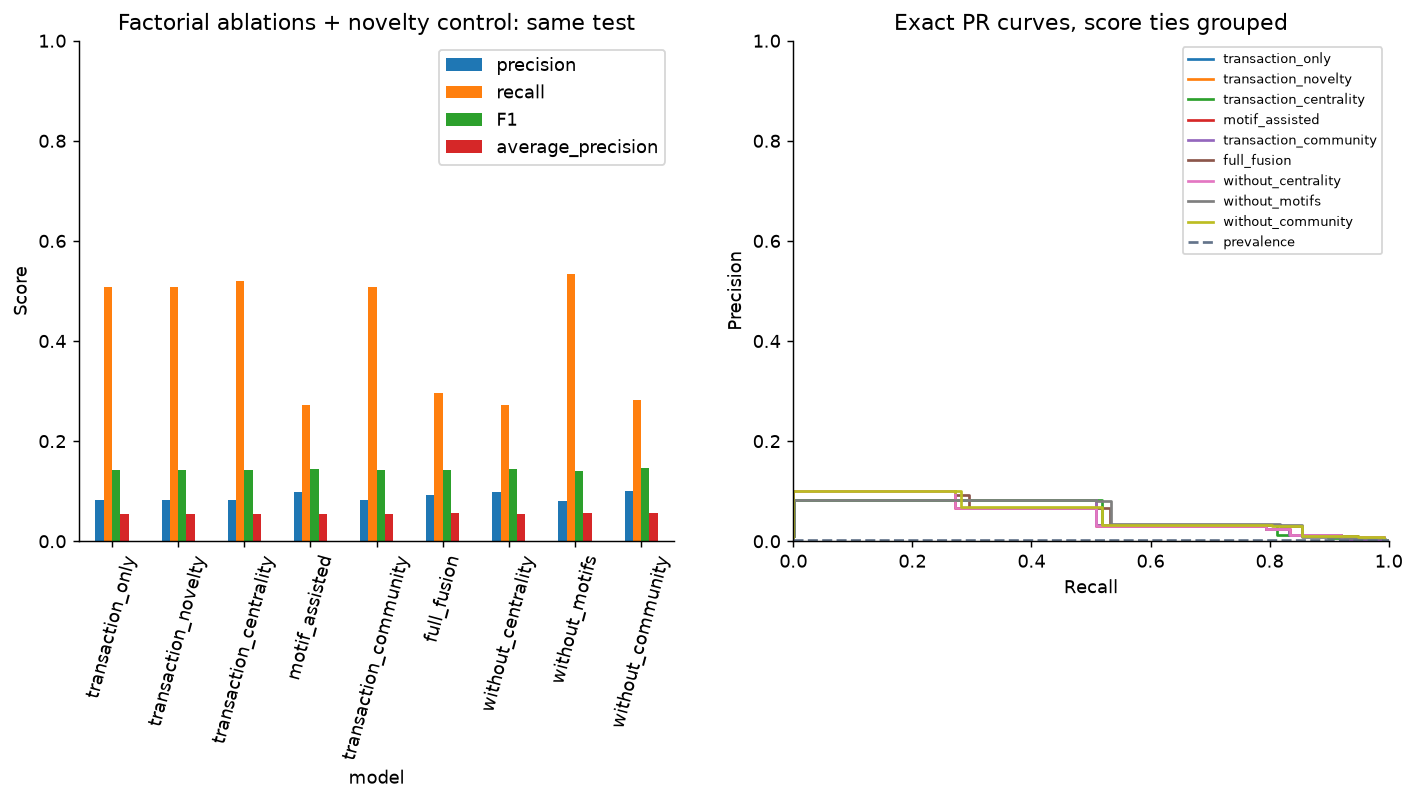

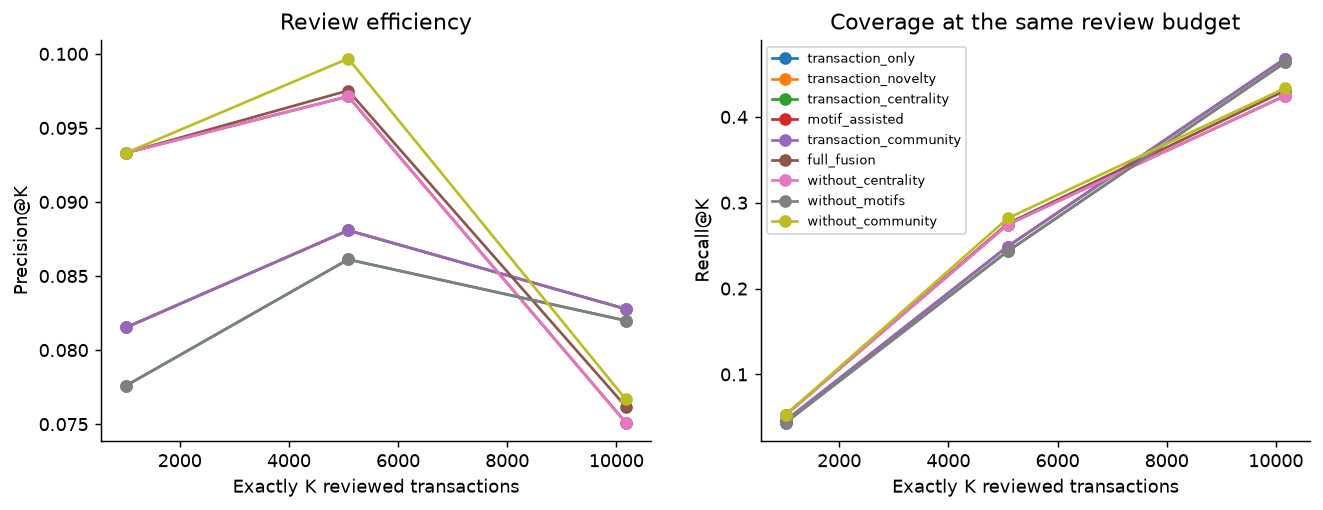

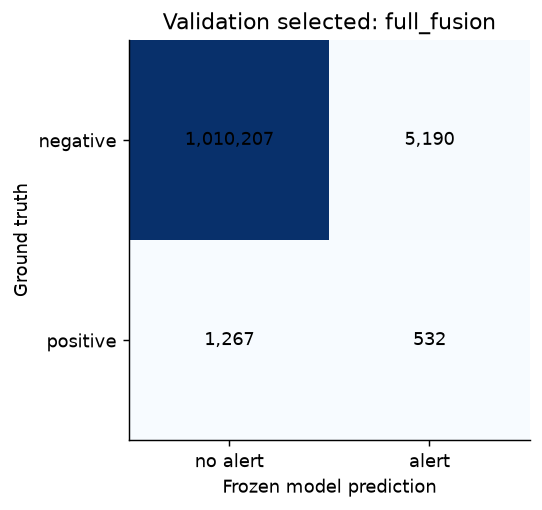

,model,threshold,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence,alert_rate,average_precision,selected_on_validation,precision_low95,precision_high95,recall_low95,recall_high95
0,transaction_only,0.5,1017196,1799,10989,914,10075,885,1005322,0.083174,0.508060,0.142947,0.001769,0.010803,0.053897,False,0.078156,0.088484,0.484966,0.531120
1,transaction_novelty,0.5,1017196,1799,10989,914,10075,885,1005322,0.083174,0.508060,0.142947,0.001769,0.010803,0.053897,False,0.078156,0.088484,0.484966,0.531120
2,transaction_centrality,0.5,1017196,1799,11243,934,10309,865,1005088,0.083074,0.519177,0.143230,0.001769,0.011053,0.054386,False,0.078114,0.088319,0.496073,0.542200
3,motif_assisted,0.5,1017196,1799,5008,489,4519,1310,1010878,0.097644,0.271818,0.143676,0.001769,0.004923,0.054463,False,0.089728,0.106176,0.251762,0.292846
4,transaction_community,0.5,1017196,1799,10989,914,10075,885,1005322,0.083174,0.508060,0.142947,0.001769,0.010803,0.053897,False,0.078156,0.088484,0.484966,0.531120
5,full_fusion,0.5,1017196,1799,5722,532,5190,1267,1010207,0.092974,0.295720,0.141471,0.001769,0.005625,0.056662,True,0.085721,0.100774,0.275085,0.317226
6,without_centrality,0.5,1017196,1799,5008,489,4519,1310,1010878,0.097644,0.271818,0.143676,0.001769,0.004923,0.054463,False,0.089728,0.106176,0.251762,0.292846
7,without_motifs,0.5,1017196,1799,11875,959,10916,840,1004481,0.080758,0.533074,0.140266,0.001769,0.011674,0.055714,False,0.075992,0.085795,0.509974,0.556033
8,without_community,0.5,1017196,1799,5090,507,4583,1292,1010814,0.099607,0.281823,0.147191,0.001769,0.005004,0.056127,False,0.091679,0.108139,0.261516,0.303060


{'transactions': 1017196,
 'fraud': 1799,
 'alerts': 1883,
 'TP': 54,
 'FP': 1829,
 'FN': 1745,
 'TN': 1013568,
 'precision': 0.02867764206054169,
 'recall': 0.03001667593107282,
 'F1': 0.02933188484519283,
 'prevalence': 0.001768587371558677,
 'alert_rate': 0.0018511673266509109}

{'model': 'full_fusion',
 'threshold': 0.5,
 'transactions': 1017196,
 'fraud': 1799,
 'alerts': 5722,
 'TP': 532,
 'FP': 5190,
 'FN': 1267,
 'TN': 1010207,
 'precision': 0.092974484445998,
 'recall': 0.295719844357977,
 'F1': 0.141470549129105,
 'prevalence': 0.001768587371559,
 'alert_rate': 0.005625267893307,
 'average_precision': 0.05666196035923,
 'selected_on_validation': True,
 'precision_low95': 0.08572083163819,
 'precision_high95': 0.100774282922776,
 'recall_low95': 0.275084614149064,
 'recall_high95': 0.317225626774289}

In [12]:
from src.motif.presentation import plot_system_results

display(plot_system_results(run))
display(run.record['novelty_baseline'])
display(run.record['selected_test_metrics'])


## 12. Chứng cứ giao dịch thật

Minh họa một test alert/TP của model được validation chọn, nếu có. Graph chỉ vẽ các event thật và witness kiểm tra được; nhãn hiển thị để audit sau dự đoán. Một ví dụ không chứng minh motif gây ra mọi phần cải thiện của model. Nếu ABSTAIN/no TP/no eligible path thì ghi rõ thay vì dựng vòng giả.

TP là nhãn của giao dịch đang được quyết định; các cạnh witness trước đó có thể mang nhãn 0. Một vòng có cạnh thật vẫn cần phân biệt chứng cứ cấu trúc với kết luận toàn bộ vòng đều laundering.


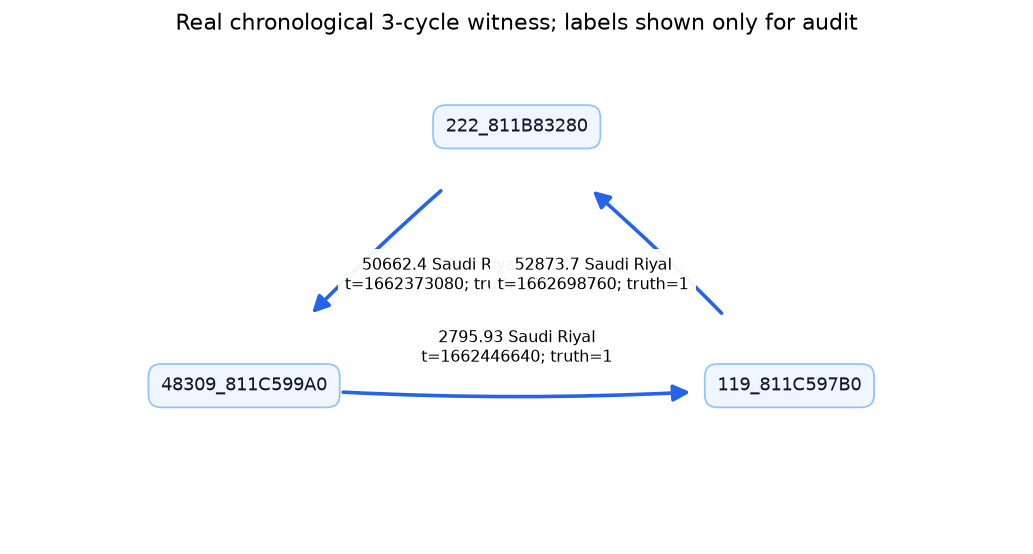

,event_id,src,dst,step,type,amount,payment_currency,isFraud,example_model,evidence_kind
0,25769829646,222_811B83280,48309_811C599A0,1662373080,ACH,50662.36,Saudi Riyal,1.0,full_fusion,chronological 3-cycle witness
1,42949725052,48309_811C599A0,119_811C597B0,1662446640,ACH,2795.93,Saudi Riyal,1.0,full_fusion,chronological 3-cycle witness
2,523986021800,119_811C597B0,222_811B83280,1662698760,ACH,52873.69,Saudi Riyal,1.0,full_fusion,chronological 3-cycle witness


In [13]:
from src.motif.presentation import system_case_evidence

display(system_case_evidence(run))


### Đọc case đã lưu — `run_20261023T165404547138Z`

Các cạnh dưới đây lấy từ `selected_case_evidence.csv` của run đã nghiệm thu. Dùng bảng này để đọc amount và thời điểm cụ thể, cùng hướng mũi tên trong hình.

| Thời điểm UTC | Nguồn → đích | Amount | Currency | Ground truth |
|---|---|---:|---|---:|
| 2022-09-05 10:18 | `222_811B83280` → `48309_811C599A0` | 50,662.36 | Saudi Riyal | 1 |
| 2022-09-06 06:44 | `48309_811C599A0` → `119_811C597B0` | 2,795.93 | Saudi Riyal | 1 |
| 2022-09-09 04:46 | `119_811C597B0` → `222_811B83280` | 52,873.69 | Saudi Riyal | 1 |

Ba cạnh tạo account cycle theo đúng thứ tự thời gian và cùng currency; giao dịch cuối là test TP của model được validation chọn. Amount từng cạnh được giữ riêng. Chứng cứ này xác nhận topology/thứ tự; truy vết cùng một khoản tiền qua mọi cạnh cần thêm giả định phân bổ dòng tiền. Case minh họa không thay thế confusion matrix trên toàn test. Khi chạy run mới, đối chiếu lại case output mới và run ID.

Trong model `full_fusion` của run này, cycle3 và relay có tree importance = 0; các tín hiệu graph được dùng chủ yếu là fan-in/out, reciprocal và PageRank. Vì vậy case trên chứng minh có witness cycle thực và một giao dịch TP, còn đóng góp dự đoán riêng của cycle/relay chưa được chứng minh. Nguồn đối chiếu: `feature_importance.csv`.


## 13. Nghiệm thu artifact và publication của run local

Verifier stream predictions và tính lại confusion/AP độc lập, kiểm tra hash của toàn bộ artifacts và full-row coverage. Chỉ khi tất cả phase/source/input/output hợp lệ mới publish latest pointer **ở máy**, không Git push. Performance yếu vẫn phải báo thật; software PASS không thay tiêu chí precision/recall của nghiệp vụ.


In [14]:
from src.motif.pipeline import finalize_full_system

display(finalize_full_system(run))


,check,result
0,status,PASS
1,scope,full
2,full_transactions,5078345
3,full_accounts,518581
4,models,9
5,test_transactions,1017196
6,test_positives,1799
7,predictions_confusion_and_AP,independently recomputed
8,artifact_hashes,PASS


## 14. Nguồn code và tài nguyên thực tế

Các hash này là source đã thực thi; sửa code cần run mới. Cell cuối đóng Spark và trả memory measurements. Notebook runner lưu output sau từng cell và đóng kernel/JVM; không khởi chạy notebook còn lại trước khi process này kết thúc.

CPU hard cap 10% áp dụng cho job. `maximum_host_cpu_percent` đo toàn máy, gồm các ứng dụng khác; `peak_job_commit_gib` đo commit của job được guard giới hạn.


In [15]:
from pandas import DataFrame

display(DataFrame(run.record['source_sha256'].items(), columns=['source', 'executed_sha256']))
display(session.close())


,source,executed_sha256
0,scripts\run_n4_notebook.py,2d6817f0ba8e84177244b491573c95c13e514f4d2b1ad4...
1,src\common\graph_utils.py,0f3927e16594eda2a2fff6b0b43c6fc7c54629a25e85fb...
2,src\common\hardware_guard.py,ee2a504ad5a78b368755426d6c4e0dd1cdad514dcdc311...
3,src\common\project_audit.py,5a4c890010d654572e3ace2300f4d7cf2fabd1f4f03e43...
4,src\common\run_evidence.py,1dea563c30efc07eea18ef605b1f28f5d2e9b75ad091d3...
5,src\common\spark_session.py,a97053f7cd3eea84dec074c0a67e46d944100a29e7376b...
6,src\common\windows_runtime.py,31ad3c51e80fb52bbaee3762ff8d938cd55db338317e05...
7,src\ibm_aml\community_detection.py,2b84430b8b85029854a3d134ee10775dc895cc217fd74b...
8,src\ibm_aml\etl.py,2602afff5b9d4bf22101f6af3b460c3377add35ce0c1af...
9,src\ibm_aml\motif_finding.py,176b8137e9a3606eed22247685be1080e2c856dab8b0c9...


,setting,value
0,dataset,ibm_aml
1,finished_utc,2026-10-23T18:04:41.118018+00:00
2,elapsed_seconds,4244.9
3,execution,Completed; performance is reported separately
4,cpu_hard_cap_percent,10
5,max_logical_cpus,2
6,job_commit_cap_gib,8.0
7,peak_job_commit_gib,6.0
8,minimum_available_ram_gib,14.37
9,maximum_host_cpu_percent,70.8


## Giới hạn kết luận

IBM notebook này đánh giá nhãn laundering của HI-Small. Không gộp F1 hai dataset, không gọi community là vòng rửa tiền thật, và không coi unalerted là hợp pháp. Cần test ngoài mẫu mới nếu muốn khẳng định khả năng tổng quát hóa. Thiết kế temporal features tham khảo [AMLworld](https://arxiv.org/html/2306.16424v3#A4); implementation/benchmark trong notebook là của repo này.
